# Notebook 10 — Recommendation Quality Evaluation

**Purpose**: fill Table `tab:recquality` in the manuscript (`sec:recquality`) with
**real** numbers, computed against **real user-interaction data** (`rated_papers.csv`,
`implicit_interactions.csv` — 774K explicit ratings + 556K implicit interactions over
~13K users), not simulated placeholders.

**Systems compared** (matching the manuscript, plus one ablation row):
1. **Popularity** — global interaction-count ranking, no personalization.
2. **BM25** — lexical retrieval against a per-user keyword query.
3. **Collaborative filtering** — implicit-feedback ALS (Hu, Koren & Volinsky, 2008) on the
   user-item matrix alone, no content/graph signal.
4. **Graph-based collaborative filtering** — the same CF scores, blended with citation-graph
   centrality (the same `graph_scores.json` signal the live system uses).
5. **Dense retrieval only** — cosine similarity between a recency-weighted user profile
   vector (same formula as `04_user_profile_agent`) and paper embeddings.
6. **Our pipeline (content-only, no CF)** — the previously deployed nb05 scoring formula
   (dense + BM25 + graph at $\lambda{=}0.5/0.2/0.3$, top-40 dense∪BM25 funnel). Kept as an
   ablation row: the gap to row 7 is the measured cost of omitting the CF signal and
   blending unnormalized signal scales.
7. **Our pipeline (hybrid)** — the manuscript's stated design: **collaborative + content +
   citation** signals fused. dense/BM25/CF top-200 union candidate funnel,
   min-max-normalized signals within the funnel, fusion weights tuned on a validation user
   split disjoint from the evaluation users. The tuning grid contains "dense alone" as a
   floor candidate, so the hybrid is never handicapped by construction. See the "Why the
   pipeline trailed Dense-alone" section for the diagnosis that motivated this redesign.

**Protocol**: chronological leave-last-out split per user (standard implicit-feedback
protocol, e.g. He et al. 2017 NCF), ALS + popularity trained on the full training log,
ranking metrics computed for a random sample of test users against the full ~240K-paper
candidate universe. No LLM calls, no API cost — everything here runs from precomputed
local artifacts (embeddings, BM25 index, graph centrality) plus a freshly trained CF model.

> **Important — do not reuse `outputs/user_profiles.json`.** That file's `user_id` keys
> (`"0"`, `"1"`, ...) do not correspond to `rated_papers.csv`'s `user_id` values, and it was
> built from each user's *full* interaction history — using it here would leak test-set
> items into the profile vector. This notebook rebuilds profile vectors from the train
> split only, self-contained, using the exact same formula.

In [1]:
# ── Dependencies ────────────────────────────────────────────────────────────
import json, os, pickle, math, re, warnings
from pathlib import Path
from typing import Dict, List, Optional
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 120

import importlib.util as _ilu, subprocess as _sp, sys as _sys
for _pkg in ["implicit"]:
    if _ilu.find_spec(_pkg.replace("-", "_")) is None:
        _sp.run([_sys.executable, "-m", "pip", "install", "-q", _pkg], check=False)
import implicit
from sklearn.feature_extraction.text import CountVectorizer


def _find(name):
    for root in ["/kaggle/input", "/kaggle/working", "..", "."]:
        r = Path(root)
        if r.exists():
            hits = list(r.rglob(name))
            if hits:
                return hits[0]
    return None


# NOTE: plain os.path.exists("/kaggle") is not reliable on Windows — it matches
# case-insensitively against any local "kaggle"-named folder on the current drive root
# (bit us once during testing: an unrelated personal "F:\Kaggle" directory). Require the
# actual Kaggle run-type env var, which only a real Kaggle kernel sets.
IS_KAGGLE = os.environ.get("KAGGLE_KERNEL_RUN_TYPE") is not None
DATA_DIR  = Path("../data")
EMB_DIR   = Path("../embeddings")
OUT_DIR   = Path("/kaggle/working") if IS_KAGGLE else Path("../outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

RNG_SEED = 13
RNG = np.random.default_rng(RNG_SEED)
print("Dependencies loaded. IS_KAGGLE =", IS_KAGGLE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 50.6 MB/s eta 0:00:00
Dependencies loaded. IS_KAGGLE = True


In [2]:
# ── Load artifacts (canonical corpus: embeddings / BM25 / graph scores share one item order) =
# Papers metadata: CSV locally (papers_metadata.csv), JSON on Kaggle (paper_metadata.json,
# the reapers2025/paper-metadata dataset used by nb04/05/07) -- same fallback as those.
_papers_p = _find("papers_metadata.csv") or _find("paper_metadata.json")
assert _papers_p is not None, "papers metadata not found (papers_metadata.csv / paper_metadata.json)"
papers_df = pd.read_csv(_papers_p) if str(_papers_p).endswith(".csv") else pd.read_json(_papers_p)
id_col = next((c for c in ["arxiv_id", "paper_id", "paperId", "id"] if c in papers_df.columns), None)
assert id_col is not None, f"no recognizable paper-id column in papers_df (columns: {list(papers_df.columns)})"
papers_df[id_col] = papers_df[id_col].astype(str)

_rated_p = _find("rated_papers.csv") or (DATA_DIR / "rated_papers.csv")
_impl_p  = _find("implicit_interactions.csv") or (DATA_DIR / "implicit_interactions.csv")
assert Path(_rated_p).exists() and Path(_impl_p).exists(), \
    "rated_papers.csv / implicit_interactions.csv not found -- attach the recommendation-system dataset"
rated_df    = pd.read_csv(_rated_p)
implicit_df = pd.read_csv(_impl_p)

# Embeddings: e5 (nb03) on Kaggle if present, else the full 1024-d GTE fallback used locally
# by nb04/nb05 — same convention, so "dense" here matches the live system's embedding space.
_e5_emb, _e5_map = _find("paper_embeddings_e5.npy"), _find("paper_id_mapping_e5.json")
if _e5_emb and _e5_map:
    emb_matrix = np.load(_e5_emb)
    id_mapping = json.load(open(_e5_map, encoding="utf-8"))
else:
    _emb_p = _find("paper_embeddings_full.npy") or (EMB_DIR / "paper_embeddings_full.npy")
    _map_p = _find("paper_id_mapping.json") or (EMB_DIR / "paper_id_mapping.json")
    assert Path(_emb_p).exists() and Path(_map_p).exists(), \
        "embeddings not found (paper_embeddings_full.npy / paper_id_mapping.json) -- attach the acl-embeddings dataset"
    emb_matrix = np.load(_emb_p)
    id_mapping = json.load(open(_map_p, encoding="utf-8"))
emb_matrix = emb_matrix.astype(np.float32)

_gs_p = _find("graph_scores.json") or (OUT_DIR / "graph_scores.json")
if Path(_gs_p).exists():
    graph_scores = json.load(open(_gs_p, encoding="utf-8"))
else:
    print("WARNING: graph_scores.json NOT found -- attach the rationale-subset dataset. "
          "Running with all-zero graph scores (degrades 'Graph-based CF' to plain CF, "
          "and drops the graph term from 'Our pipeline').")
    graph_scores = {}

# Canonical item universe: id_mapping's insertion order is its own row-index order
# (id_mapping[pid] == i for the i-th key inserted) — verified once, so dense / bm25 / graph
# scores can all be indexed by one shared integer position, no per-item dict lookups later.
ITEM_IDS = list(id_mapping.keys())
N_ITEMS  = len(ITEM_IDS)
assert all(id_mapping[pid] == i for i, pid in enumerate(ITEM_IDS[:1000])), \
    "id_mapping insertion order no longer matches its own index values — do not assume positional alignment"
EMB        = emb_matrix
EMB_NORMS  = np.linalg.norm(EMB, axis=1) + 1e-9
GRAPH_VEC  = np.array([graph_scores.get(pid, 0.0) for pid in ITEM_IDS], dtype=np.float32)
ITEM_POS   = {pid: i for i, pid in enumerate(ITEM_IDS)}

print(f"papers={len(papers_df)} (id_col={id_col}) rated={len(rated_df)} implicit={len(implicit_df)} "
      f"items={N_ITEMS} emb={EMB.shape} graph_scores_nonzero={int((GRAPH_VEC>0).sum())}")

papers=239618 (id_col=arxiv_id) rated=774092 implicit=556324 items=239618 emb=(239618, 1024) graph_scores_nonzero=215701


### Fast BM25 (precomputed sparse weight matrix)

`rank_bm25`'s `get_scores()` re-scans the whole ~240K-doc corpus per call (~4.7s/query
measured locally); at 500 users that is ~40 minutes just for BM25 and blows any reasonable
notebook cell timeout. BM25's own formula factors into a fixed per-(document, term) weight
independent of the query, so it can be precomputed **once** as a sparse matrix
(`docs x vocab`); scoring a query is then just summing the columns for its terms — a sparse
slice instead of a corpus-wide scan, milliseconds instead of seconds.

In [3]:
# ── Precompute BM25 as a sparse (docs x vocab) weight matrix, built once ──────
# Standard Robertson/Sparck-Jones BM25 (k1=1.5, b=0.75), matching rank_bm25's defaults.
_id_to_text = dict(zip(papers_df[id_col],
                       (papers_df["title"].fillna("") + " " + papers_df["abstract"].fillna(""))))
_corpus_texts = [_id_to_text.get(pid, "") for pid in ITEM_IDS]

_vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", max_features=150_000)
_TF = _vectorizer.fit_transform(_corpus_texts).tocsr()
BM25_VOCAB = _vectorizer.vocabulary_

_doc_len = np.asarray(_TF.sum(axis=1)).ravel()
_avgdl   = _doc_len.mean()
_df      = np.asarray((_TF > 0).sum(axis=0)).ravel().astype(np.float64)
_N       = _TF.shape[0]
_idf     = np.log((_N - _df + 0.5) / (_df + 0.5) + 1.0)
_avg_idf = _idf.mean()
_idf     = np.where(_idf < 0, 0.25 * _avg_idf, _idf)          # rank_bm25's epsilon floor

_k1, _b = 1.5, 0.75
_indptr, _indices = _TF.indptr, _TF.indices
_data = _TF.data.astype(np.float32)
_row_doclen = np.repeat(_doc_len, np.diff(_indptr))
_denom = _data + _k1 * (1 - _b + _b * _row_doclen / _avgdl)
_weight_data = _idf[_indices] * (_data * (_k1 + 1)) / _denom
# Reuse TF's CSR sparsity pattern (indptr/indices are row-indexed) with the new weighted
# values, then convert to CSC for fast column slicing during per-user scoring below.
BM25_W = sparse.csr_matrix((_weight_data, _indices, _indptr), shape=_TF.shape).tocsc()

print(f"BM25 weight matrix: {BM25_W.shape}, vocab={len(BM25_VOCAB)}, nnz={BM25_W.nnz}")

BM25 weight matrix: (239618, 150000), vocab=150000, nnz=23716982


## 1. Interaction pool, chronological split, and disliked-item filtering

Positive signal = all implicit interactions (view/click) + explicit `rating == 1` (weighted
higher: a user who both viewed *and* explicitly liked a paper gives a stronger signal than a
view alone). Explicit `rating == -1` is not used as CF training signal (standard for
implicit-feedback CF, which typically only distinguishes observed-vs-unobserved), but **is**
used to exclude disliked papers from every system's candidate list for that user — a paper a
user explicitly disliked should never be recommended back to them, regardless of what any
scoring function says.

Split: for each user with enough history, sort interactions chronologically and hold out the
single most recent one as the test item (leave-last-out; He et al., 2017). CF and popularity
are trained on the **full** training log across all qualifying users; only a random sample of
test users is used for the (expensive) full-corpus ranking pass below.

In [4]:
# ── Build the positive-interaction pool ───────────────────────────────────────
MIN_INTERACTIONS = 5   # per user: >=4 train + 1 held-out test item

imp = implicit_df[["user_id", "arxiv_id", "time"]].copy()
imp["weight"] = 1.0

pos_rated = rated_df[rated_df["rating"] == 1][["user_id", "arxiv_id", "time"]].copy()
pos_rated["weight"] = 2.0

neg_rated = rated_df[rated_df["rating"] == -1][["user_id", "arxiv_id"]].copy()
disliked = defaultdict(set)
for u, pid in zip(neg_rated["user_id"], neg_rated["arxiv_id"]):
    if pid in ITEM_POS:
        disliked[int(u)].add(pid)

pool = pd.concat([imp, pos_rated], ignore_index=True)
pool["arxiv_id"] = pool["arxiv_id"].astype(str)
pool = pool[pool["arxiv_id"].isin(ITEM_POS)]                     # corpus coverage only
pool["time"] = pd.to_datetime(pool["time"], errors="coerce")
pool = pool.dropna(subset=["time"])                               # drop unparseable timestamps (~1%)
pool = (pool.sort_values("weight", ascending=False)
             .drop_duplicates(subset=["user_id", "arxiv_id"], keep="first"))  # dedup, keep stronger signal

print(f"positive interaction pool: {len(pool)} rows, {pool['user_id'].nunique()} users, "
      f"{pool['arxiv_id'].nunique()} items (corpus-covered)")

# ── Chronological per-user split ──────────────────────────────────────────────
train_rows, test_rows = [], []
for uid, g in pool.groupby("user_id"):
    if len(g) < MIN_INTERACTIONS:
        continue
    g = g.sort_values("time")
    test_rows.append(g.iloc[-1])
    train_rows.append(g.iloc[:-1])

train_df = pd.concat(train_rows, ignore_index=True) if train_rows else pd.DataFrame()
test_df  = pd.DataFrame(test_rows).reset_index(drop=True) if test_rows else pd.DataFrame()
train_df["user_id"] = train_df["user_id"].astype(int)
test_df["user_id"]  = test_df["user_id"].astype(int)

qualifying_users = sorted(test_df["user_id"].unique().tolist())
print(f"qualifying users (>= {MIN_INTERACTIONS} interactions): {len(qualifying_users)}")
print(f"train rows: {len(train_df)}  test rows (1 per user): {len(test_df)}")

positive interaction pool: 882618 rows, 17358 users, 217787 items (corpus-covered)
qualifying users (>= 5 interactions): 14861
train rows: 862322  test rows (1 per user): 14861


## 2. Popularity & implicit-ALS collaborative filtering (trained on the full training log)

In [5]:
# ── Popularity (global, from the full train log) ─────────────────────────────
pop_counts = train_df["arxiv_id"].value_counts()
POP_VEC = np.zeros(N_ITEMS, dtype=np.float32)
for pid, c in pop_counts.items():
    POP_VEC[ITEM_POS[pid]] = c

# ── Implicit-feedback ALS (Hu, Koren & Volinsky 2008) ─────────────────────────
ALPHA_CONFIDENCE = 40.0
N_FACTORS        = 64
ALS_ITERATIONS    = 15
ALS_REGULARIZATION = 0.01

uid_list = qualifying_users
uid_pos  = {u: i for i, u in enumerate(uid_list)}
n_users  = len(uid_list)

rows = train_df["user_id"].map(uid_pos).to_numpy()
cols = train_df["arxiv_id"].map(ITEM_POS).to_numpy()
conf  = np.full(len(train_df), 1.0 + ALPHA_CONFIDENCE, dtype=np.float32)
train_csr = sparse.csr_matrix((conf, (rows, cols)), shape=(n_users, N_ITEMS))

als_model = implicit.als.AlternatingLeastSquares(
    factors=N_FACTORS, regularization=ALS_REGULARIZATION, iterations=ALS_ITERATIONS,
    random_state=RNG_SEED,
)
try:
    als_model.fit(train_csr, show_progress=False)
except TypeError:
    als_model.fit(train_csr)

user_train_items = defaultdict(set)   # for filtering already-seen items out of every ranking
for u, pid in zip(train_df["user_id"], train_df["arxiv_id"]):
    user_train_items[int(u)].add(pid)

print(f"ALS trained: {n_users} users x {N_ITEMS} items, {N_FACTORS} factors, "
      f"{ALS_ITERATIONS} iterations, {train_csr.nnz} nonzero training interactions")

# ── Persist as a SHARED artifact so nb05/nb07 load this exact trained model instead of
# retraining their own copy. item_factors rows are aligned to the canonical ITEM_IDS order
# (paper_id_mapping.json insertion order, shared by nb03/04/05/07/10 -- verified earlier in
# this notebook), so nb05/nb07 can index it directly with their own existing id_mapping,
# no extra lookup table needed for items. user_factors rows are aligned to als_user_ids.json
# (a user_id is cold-start / has no CF vector if it is not in that list).
np.save(OUT_DIR / "als_item_factors.npy", als_model.item_factors.astype(np.float32))
np.save(OUT_DIR / "als_user_factors.npy", als_model.user_factors.astype(np.float32))
with open(OUT_DIR / "als_user_ids.json", "w", encoding="utf-8") as f:
    json.dump(uid_list, f)
with open(OUT_DIR / "als_model_meta.json", "w", encoding="utf-8") as f:
    json.dump({
        "n_users": n_users, "n_items": N_ITEMS, "factors": N_FACTORS,
        "regularization": ALS_REGULARIZATION, "iterations": ALS_ITERATIONS,
        "alpha_confidence": ALPHA_CONFIDENCE, "min_interactions": MIN_INTERACTIONS,
        "trained_on_interactions": int(train_csr.nnz),
        "note": ("als_item_factors.npy rows are aligned to the canonical ITEM_IDS order "
                 "(paper_id_mapping.json insertion order). als_user_factors.npy rows are "
                 "aligned to als_user_ids.json (row i is that user's factor vector); a "
                 "user_id absent from als_user_ids.json has no CF vector (cold-start -- "
                 "fall back to content-only signals for that user, same as the base "
                 "paper's RAG fallback for cold users)."),
    }, f, indent=2)
print(f"Saved shared CF artifacts to {OUT_DIR}: als_item_factors.npy {als_model.item_factors.shape}, "
      f"als_user_factors.npy {als_model.user_factors.shape}, als_user_ids.json ({len(uid_list)} users), "
      f"als_model_meta.json")

ALS trained: 14861 users x 239618 items, 64 factors, 15 iterations, 862322 nonzero training interactions
Saved shared CF artifacts to /kaggle/working: als_item_factors.npy (239618, 64), als_user_factors.npy (14861, 64), als_user_ids.json (14861 users), als_model_meta.json


## 3. Per-user candidate scoring for the five baselines + our pipeline

For each evaluated user: rebuild a recency-weighted profile vector from their **train split
only** (identical formula to `04_user_profile_agent`: exponential temporal decay,
$\lambda{=}0.1$, upweighted by interaction strength), extract a BM25 keyword query from
their train papers' titles, then score the full ~240K-item universe under each system.

In [6]:
# ── Shared per-user helpers ────────────────────────────────────────────────────
DECAY_LAMBDA = 0.1
STOP_WORDS = {"a", "an", "the", "of", "in", "on", "for", "and", "or", "to", "with",
              "from", "via", "using", "based", "towards", "this", "that", "these"}
LAMBDA1, LAMBDA2, LAMBDA3 = 0.5, 0.2, 0.3   # same weights as HybridRetrievalAgent (nb05)


def user_profile_vector(rows: pd.DataFrame) -> Optional[np.ndarray]:
    """Recency + strength weighted mean embedding, reference time = user's own last
    train-set interaction (avoids leaking global future information)."""
    ref_time = rows["time"].max()
    embs, weights = [], []
    for pid, w, t in zip(rows["arxiv_id"], rows["weight"], rows["time"]):
        pos = ITEM_POS.get(pid)
        if pos is None:
            continue
        days = max(0.0, (ref_time - t).days)
        embs.append(EMB[pos])
        weights.append(math.exp(-DECAY_LAMBDA * days) * max(0.1, float(w)))
    if not embs:
        return None
    weights = np.asarray(weights); weights /= weights.sum()
    vec = np.average(np.asarray(embs), axis=0, weights=weights)
    n = np.linalg.norm(vec)
    return vec / n if n > 0 else vec


def user_bm25_query(rows: pd.DataFrame, top_k: int = 20) -> List[str]:
    sub = papers_df[papers_df[id_col].isin(rows["arxiv_id"])]
    words = []
    for title in sub["title"].dropna():
        toks = re.findall(r"[A-Za-z][a-z]+", str(title).lower())
        words.extend(w for w in toks if w not in STOP_WORDS and len(w) > 3)
    return [w for w, _ in Counter(words).most_common(top_k)]


def score_dense(profile_vec: Optional[np.ndarray]) -> np.ndarray:
    if profile_vec is None:
        return np.zeros(N_ITEMS, dtype=np.float32)
    return (EMB @ profile_vec) / EMB_NORMS


def score_bm25(keywords: List[str]) -> np.ndarray:
    term_idxs = [BM25_VOCAB[w] for w in keywords if w in BM25_VOCAB]
    if not term_idxs:
        return np.zeros(N_ITEMS, dtype=np.float32)
    scores = np.asarray(BM25_W[:, term_idxs].sum(axis=1)).ravel().astype(np.float32)
    m = scores.max()
    return scores / m if m > 0 else scores


def score_cf(u_idx: int) -> np.ndarray:
    return als_model.user_factors[u_idx] @ als_model.item_factors.T


def minmax(v: np.ndarray) -> np.ndarray:
    lo, hi = v.min(), v.max()
    return (v - lo) / (hi - lo) if hi > lo else np.zeros_like(v)


print("Scoring helpers defined.")

Scoring helpers defined.


### Why the pipeline trailed Dense-alone, and what this redesign fixes

The first two rounds of results (kept in the summary at the bottom) showed "Our pipeline"
*below* Dense-alone and even below BM25. Three diagnosed causes, none of them "the system
is just worse":

1. **The pipeline had no collaborative signal.** The manuscript describes the system as a
   hybrid of **collaborative + content + citation** signals, and the ground truth in this
   protocol is *behavioral* (the paper the user actually interacted with next) — but the
   scored pipeline blended only dense+BM25+graph. A content-only blend competing against
   behavioral ground truth is exactly the mismatch the project plan called
   out; the fix there — restore a CF signal and fuse — is what this redesign implements.
   The CF model was already trained in this notebook; it was used as a baseline but never
   fused into the pipeline.
2. **Scale mismatch made the fusion weights meaningless.** Raw profile-cosine over this
   anisotropic embedding space spans ~0.76–0.87 (effective discriminative range ~0.11),
   while BM25 and graph centrality are normalized to 0–1. In a raw-scale blend,
   $\lambda_{2,3}=0.2/0.3$ on BM25/graph outweigh dense's entire useful range, so the blend
   mostly reordered by the weaker signals. Signals are now min-max normalized **within the
   candidate shortlist** before blending, so every weight operates on the same [0,1] units.
3. **The 150-user validation sweep selected noise.** It picked $(1.0, \lambda_3{=}0.15)$,
   which then scored *worse* on the eval split (0.0085) than the deployed weights it
   replaced (0.0108). The sweep now uses 500 validation users (still disjoint from the
   eval users), and the grid still contains "dense alone" as a floor candidate.

The candidate funnel also grows from top-40 dense ∪ top-40 BM25 to top-200 dense ∪ BM25 ∪
CF: the funnel's candidate recall is a hard ceiling on every metric, and the cell below
prints that ceiling explicitly so it can be reported rather than guessed at.

In [7]:
# ── Validation sweep: tune hybrid-fusion weights (dense, BM25, CF, graph) ─────
# Redesigned per the markdown above: CF joins the fusion, signals are min-max normalized
# within the candidate shortlist, and the validation sample grows 150 -> 500 users. The
# grid still contains (1,0,0,0) == Dense-alone as a floor candidate, so on validation the
# tuned hybrid can only tie or beat the strongest single signal, never be handicapped by
# construction. Weights are selected on validation users only; eval_users (next cell) are
# drawn from the disjoint remainder.
VAL_N_USERS     = min(500, max(1, len(qualifying_users) // 4))
CAND_TOPK       = 200   # per-signal candidate depth for the hybrid funnel (dense/BM25/CF)
DENSE_BM25_TOPK = 40    # the OLD content-only funnel depth, kept for its ablation row below

# (w_dense, w_bm25, w_cf, w_graph) over shortlist-normalized signals
WEIGHT_GRID = [
    (1.00, 0.00, 0.00, 0.00),   # dense alone (floor guard)
    (0.00, 0.00, 1.00, 0.00),   # CF alone
    (0.80, 0.00, 0.20, 0.00),
    (0.70, 0.00, 0.30, 0.00),
    (0.60, 0.00, 0.40, 0.00),
    (0.50, 0.00, 0.50, 0.00),
    (0.40, 0.00, 0.60, 0.00),
    (0.70, 0.10, 0.20, 0.00),
    (0.60, 0.10, 0.30, 0.00),
    (0.50, 0.10, 0.40, 0.00),
    (0.65, 0.00, 0.30, 0.05),
    (0.60, 0.10, 0.25, 0.05),
    (0.55, 0.00, 0.35, 0.10),
    (0.50, 0.20, 0.00, 0.30),   # deployed content-only weights, on normalized signals
]

def _ndcg10(predicted, relevant):
    rel_set = set(relevant)
    dcg = sum(1 / np.log2(i + 2) for i, pid in enumerate(predicted[:10]) if pid in rel_set)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel_set), 10)))
    return dcg / idcg if idcg > 0 else 0.0


def user_seen_mask(u):
    seen = user_train_items.get(u, set()) | disliked.get(u, set())
    mask = np.ones(N_ITEMS, dtype=bool)
    for pid in seen:
        pos = ITEM_POS.get(pid)
        if pos is not None:
            mask[pos] = False
    return mask


def hybrid_candidates(mask, dense_full, bm25_full, cf_full, k=None):
    """The hybrid funnel: union of the top-k unseen items from each signal family."""
    k = k or CAND_TOPK
    tops = []
    for sig in (dense_full, bm25_full, cf_full):
        masked = np.where(mask, sig, -np.inf)
        tops.append(np.argpartition(-masked, k)[:k])
    return np.union1d(np.union1d(tops[0], tops[1]), tops[2])


def normalized_signals(cand, dense_full, bm25_full, cf_full):
    """Min-max normalize each signal within the candidate shortlist -> comparable [0,1]."""
    out = []
    for sig in (dense_full, bm25_full, cf_full, GRAPH_VEC):
        sub = sig[cand].astype(np.float64)
        lo, hi = sub.min(), sub.max()
        out.append((sub - lo) / (hi - lo) if hi > lo else np.zeros_like(sub))
    return out   # dense_n, bm25_n, cf_n, graph_n over cand positions


val_users = RNG.choice(qualifying_users, size=VAL_N_USERS, replace=False).tolist()
_val_excl = set(val_users)
val_pool = [u for u in qualifying_users if u not in _val_excl]   # eval_users below draws only from here

_train_rows_by_user_val = {u: g for u, g in train_df.groupby("user_id") if u in _val_excl}
_test_item_for_user_val = dict(zip(test_df["user_id"], test_df["arxiv_id"]))

grid_ndcg10 = {w: [] for w in WEIGHT_GRID}
shortlist_hits, n_val_scored = 0, 0
for u in val_users:
    rows = _train_rows_by_user_val.get(u)
    if rows is None or rows.empty:
        continue
    mask = user_seen_mask(u)
    dense_full = score_dense(user_profile_vector(rows))
    bm25_full  = score_bm25(user_bm25_query(rows))
    cf_full    = score_cf(uid_pos[u])

    cand = hybrid_candidates(mask, dense_full, bm25_full, cf_full)
    dense_n, bm25_n, cf_n, graph_n = normalized_signals(cand, dense_full, bm25_full, cf_full)

    relevant = [_test_item_for_user_val[u]]
    rel_pos = ITEM_POS.get(relevant[0])
    if rel_pos is not None and rel_pos in cand:
        shortlist_hits += 1
    n_val_scored += 1

    for w in WEIGHT_GRID:
        fused = w[0] * dense_n + w[1] * bm25_n + w[2] * cf_n + w[3] * graph_n
        order = np.argsort(-fused)[:10]
        predicted = [ITEM_IDS[cand[i]] for i in order]
        grid_ndcg10[w].append(_ndcg10(predicted, relevant))

grid_mean = {w: (float(np.mean(v)) if v else 0.0) for w, v in grid_ndcg10.items()}
W_TUNED = max(grid_mean, key=grid_mean.get)

print(f"Hybrid-funnel candidate recall on validation ({n_val_scored} users): "
      f"{shortlist_hits / max(1, n_val_scored):.1%} of test items inside the "
      f"dense/BM25/CF top-{CAND_TOPK} union shortlist (hard ceiling on every metric below)")
print(f"\nValidation NDCG@10 by (w_dense, w_bm25, w_cf, w_graph), {n_val_scored} users:")
for w, m in sorted(grid_mean.items(), key=lambda kv: -kv[1]):
    tag = ""
    if w == (1.00, 0.00, 0.00, 0.00): tag = "  <- dense alone"
    if w == (0.00, 0.00, 1.00, 0.00): tag = "  <- CF alone"
    if w == (0.50, 0.20, 0.00, 0.30): tag = "  <- deployed content-only weights"
    print(f"  {w}: {m:.4f}{tag}")
print(f"\nSelected on validation (disjoint from eval_users below): {W_TUNED}")

Hybrid-funnel candidate recall on validation (500 users): 33.6% of test items inside the dense/BM25/CF top-200 union shortlist (hard ceiling on every metric below)

Validation NDCG@10 by (w_dense, w_bm25, w_cf, w_graph), 500 users:
  (0.6, 0.1, 0.3, 0.0): 0.0185
  (1.0, 0.0, 0.0, 0.0): 0.0179  <- dense alone
  (0.7, 0.1, 0.2, 0.0): 0.0161
  (0.6, 0.1, 0.25, 0.05): 0.0160
  (0.7, 0.0, 0.3, 0.0): 0.0152
  (0.8, 0.0, 0.2, 0.0): 0.0147
  (0.5, 0.1, 0.4, 0.0): 0.0146
  (0.6, 0.0, 0.4, 0.0): 0.0141
  (0.65, 0.0, 0.3, 0.05): 0.0137
  (0.55, 0.0, 0.35, 0.1): 0.0126
  (0.5, 0.0, 0.5, 0.0): 0.0121
  (0.5, 0.2, 0.0, 0.3): 0.0085  <- deployed content-only weights
  (0.4, 0.0, 0.6, 0.0): 0.0080
  (0.0, 0.0, 1.0, 0.0): 0.0029  <- CF alone

Selected on validation (disjoint from eval_users below): (0.6, 0.1, 0.3, 0.0)


In [8]:
# ── Evaluate all systems for a random sample of qualifying test users ────────
# Baselines rank the full ~240K-item universe. The two "Our pipeline" rows use the
# system's own candidate-generation funnel, then re-rank inside it:
#   * "Our pipeline (content-only, no CF)" -- the previously deployed nb05 design:
#     top-40 dense / top-40 BM25 union shortlist, raw-scale blend with the deployed
#     lambda=(0.5, 0.2, 0.3). Kept as an ablation row: it is what earlier runs of this
#     notebook reported as "Our pipeline", and the gap to the hybrid row below is the
#     measured cost of (a) missing the CF signal and (b) blending unnormalized signal
#     scales (both diagnosed in the sweep cell's markdown).
#   * "Our pipeline (hybrid)" -- the manuscript's actual system description
#     (collaborative + content + citation): dense/BM25/CF top-200 union funnel,
#     shortlist-normalized signals, fusion weights selected on the disjoint validation
#     split above. No eval user was used anywhere in tuning.
EVAL_N_USERS = min(500, len(val_pool))
eval_users = RNG.choice(val_pool, size=EVAL_N_USERS, replace=False).tolist()   # disjoint from val_users

test_item_for_user = dict(zip(test_df["user_id"], test_df["arxiv_id"]))
train_rows_by_user = {u: g for u, g in train_df.groupby("user_id")}

SYSTEM_NAMES = ["Popularity", "BM25", "Collaborative filtering",
                "Graph-based collaborative filtering", "Dense retrieval only",
                "Our pipeline (content-only, no CF)", "Our pipeline (hybrid)"]
per_user_rankings = {name: {} for name in SYSTEM_NAMES}   # name -> {user_id: ranked arxiv_id list}

eval_shortlist_hits = 0
for u in eval_users:
    rows = train_rows_by_user.get(u)
    if rows is None or rows.empty:
        continue
    mask = user_seen_mask(u)

    dense_full = score_dense(user_profile_vector(rows))
    bm25_full  = score_bm25(user_bm25_query(rows))
    cf_full    = score_cf(uid_pos[u])

    scores = {
        "Popularity": POP_VEC.copy(),
        "BM25": bm25_full.copy(),
        "Collaborative filtering": cf_full.copy(),
        "Graph-based collaborative filtering": 0.7 * minmax(cf_full) + 0.3 * GRAPH_VEC,
        "Dense retrieval only": dense_full.copy(),
    }

    # Old content-only funnel (ablation row): top-40 dense / top-40 BM25 union,
    # raw-scale blend with the deployed weights -- unchanged from the earlier runs.
    masked_dense = np.where(mask, dense_full, -np.inf)
    masked_bm25  = np.where(mask, bm25_full, -np.inf)
    old_shortlist = np.union1d(
        np.argpartition(-masked_dense, DENSE_BM25_TOPK)[:DENSE_BM25_TOPK],
        np.argpartition(-masked_bm25, DENSE_BM25_TOPK)[:DENSE_BM25_TOPK])
    old_mask = np.zeros(N_ITEMS, dtype=bool)
    old_mask[old_shortlist] = True
    scores["Our pipeline (content-only, no CF)"] = np.where(
        old_mask, LAMBDA1 * dense_full + LAMBDA2 * bm25_full + LAMBDA3 * GRAPH_VEC, -np.inf)

    # Hybrid pipeline: dense/BM25/CF funnel, shortlist-normalized signals, tuned fusion.
    cand = hybrid_candidates(mask, dense_full, bm25_full, cf_full)
    dense_n, bm25_n, cf_n, graph_n = normalized_signals(cand, dense_full, bm25_full, cf_full)
    fused = (W_TUNED[0] * dense_n + W_TUNED[1] * bm25_n
             + W_TUNED[2] * cf_n + W_TUNED[3] * graph_n)
    hybrid_scores = np.full(N_ITEMS, -np.inf, dtype=np.float64)
    hybrid_scores[cand] = fused
    scores["Our pipeline (hybrid)"] = hybrid_scores

    rel_pos = ITEM_POS.get(test_item_for_user[u])
    if rel_pos is not None and rel_pos in cand:
        eval_shortlist_hits += 1

    for name, s in scores.items():
        if name not in ("Our pipeline (content-only, no CF)", "Our pipeline (hybrid)"):
            s = np.where(mask, s, -np.inf)
        top_idx = np.argpartition(-s, 50)[:50]
        top_idx = top_idx[np.argsort(-s[top_idx])]
        per_user_rankings[name][u] = [ITEM_IDS[i] for i in top_idx if np.isfinite(s[i])]

print(f"Scored {len(eval_users)} users across {len(SYSTEM_NAMES)} systems.")
print(f"Hybrid-funnel candidate recall on eval users: "
      f"{eval_shortlist_hits / max(1, len(eval_users)):.1%} of test items inside the "
      f"dense/BM25/CF top-{CAND_TOPK} union shortlist")

Scored 500 users across 7 systems.
Hybrid-funnel candidate recall on eval users: 36.0% of test items inside the dense/BM25/CF top-200 union shortlist


## 4. Metrics: NDCG@K, Recall@K, MRR, intra-list diversity, novelty

In [9]:
# ── Metric functions ──────────────────────────────────────────────────────────
def ndcg_at_k(predicted, relevant, k):
    predicted_k, rel_set = predicted[:k], set(relevant)
    dcg = sum(1 / np.log2(i + 2) for i, pid in enumerate(predicted_k) if pid in rel_set)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel_set), k)))
    return dcg / idcg if idcg > 0 else 0.0


def recall_at_k(predicted, relevant, k):
    return len(set(predicted[:k]) & set(relevant)) / len(relevant) if relevant else 0.0


def mrr(predicted, relevant):
    rel_set = set(relevant)
    for rank, pid in enumerate(predicted, start=1):
        if pid in rel_set:
            return 1.0 / rank
    return 0.0


def intra_list_diversity(predicted_ids, k=10):
    idxs = [ITEM_POS[p] for p in predicted_ids[:k] if p in ITEM_POS]
    if len(idxs) < 2:
        return 0.0
    e = EMB[idxs]
    e = e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-9)
    sim = e @ e.T
    n = len(idxs)
    mean_sim = (sim.sum() - n) / (n * (n - 1))
    return 1.0 - float(mean_sim)


N_TRAIN_TOTAL = len(train_df)
def novelty(predicted_ids, k=10):
    """Self-information novelty (Zhou et al., 2010): mean -log2(popularity probability)
    of the top-k recommended items; higher = recommends less-popular (more novel) papers."""
    vals = []
    for pid in predicted_ids[:k]:
        c = pop_counts.get(pid, 0)
        p = (c + 1) / (N_TRAIN_TOTAL + N_ITEMS)   # Laplace-smoothed popularity probability
        vals.append(-np.log2(p))
    return float(np.mean(vals)) if vals else 0.0


def evaluate_system(rankings: Dict[int, List[str]], ks=(5, 10, 20)) -> Dict[str, float]:
    sums = defaultdict(float)
    n = 0
    for u, predicted in rankings.items():
        relevant = [test_item_for_user[u]]
        for k in ks:
            sums[f"NDCG@{k}"]   += ndcg_at_k(predicted, relevant, k)
            sums[f"Recall@{k}"] += recall_at_k(predicted, relevant, k)
        sums["MRR"]     += mrr(predicted, relevant)
        sums["ILD"]     += intra_list_diversity(predicted, k=10)
        sums["Novelty"] += novelty(predicted, k=10)
        n += 1
    return {k: round(v / n, 4) for k, v in sums.items()} if n else {}


results = {name: evaluate_system(per_user_rankings[name]) for name in SYSTEM_NAMES}
for name, m in results.items():
    print(f"\n{name}:")
    for k, v in m.items():
        print(f"  {k:12s}: {v}")


Popularity:
  NDCG@5      : 0.0
  Recall@5    : 0.0
  NDCG@10     : 0.0
  Recall@10   : 0.0
  NDCG@20     : 0.0024
  Recall@20   : 0.01
  MRR         : 0.0008
  ILD         : 0.135
  Novelty     : 11.965

BM25:
  NDCG@5      : 0.0108
  Recall@5    : 0.018
  NDCG@10     : 0.0128
  Recall@10   : 0.024
  NDCG@20     : 0.0154
  Recall@20   : 0.034
  MRR         : 0.011
  ILD         : 0.1303
  Novelty     : 16.8356

Collaborative filtering:
  NDCG@5      : 0.0101
  Recall@5    : 0.014
  NDCG@10     : 0.012
  Recall@10   : 0.02
  NDCG@20     : 0.0155
  Recall@20   : 0.034
  MRR         : 0.0113
  ILD         : 0.1423
  Novelty     : 14.3774

Graph-based collaborative filtering:
  NDCG@5      : 0.0099
  Recall@5    : 0.014
  NDCG@10     : 0.0124
  Recall@10   : 0.022
  NDCG@20     : 0.0134
  Recall@20   : 0.026
  MRR         : 0.0106
  ILD         : 0.1433
  Novelty     : 14.3408

Dense retrieval only:
  NDCG@5      : 0.0112
  Recall@5    : 0.016
  NDCG@10     : 0.0163
  Recall@10   : 0.032

## 5. Results table (paper-ready) + figure + export

In [10]:
# ── Table matching manuscript tab:recquality ──────────────────────────────────
table_cols = ["NDCG@10", "Recall@10", "MRR", "ILD", "Novelty"]
table_df = pd.DataFrame({name: {c: results[name].get(c, float("nan")) for c in table_cols}
                          for name in SYSTEM_NAMES}).T
table_df.index.name = "System"
print(table_df.to_string())
table_df.to_csv(OUT_DIR / "recquality_results.csv")

with open(OUT_DIR / "recquality_results.json", "w", encoding="utf-8") as f:
    json.dump({
        "eval_n_users": EVAL_N_USERS,
        "n_qualifying_users": len(qualifying_users),
        "min_interactions": MIN_INTERACTIONS,
        "als_factors": N_FACTORS,
        "als_iterations": ALS_ITERATIONS,
        "hybrid_cand_topk": CAND_TOPK,
        "hybrid_weights_tuned": list(W_TUNED),
        "hybrid_weight_grid_val_ndcg10": {str(k): v for k, v in grid_mean.items()},
        "hybrid_funnel_recall_eval": round(eval_shortlist_hits / max(1, len(eval_users)), 4),
        "results": results,
    }, f, indent=2)
print(f"\nSaved: {OUT_DIR / 'recquality_results.csv'}, {OUT_DIR / 'recquality_results.json'}")

                                     NDCG@10  Recall@10     MRR     ILD  Novelty
System                                                                          
Popularity                            0.0000      0.000  0.0008  0.1350  11.9650
BM25                                  0.0128      0.024  0.0110  0.1303  16.8356
Collaborative filtering               0.0120      0.020  0.0113  0.1423  14.3774
Graph-based collaborative filtering   0.0124      0.022  0.0106  0.1433  14.3408
Dense retrieval only                  0.0163      0.032  0.0141  0.0998  17.1434
Our pipeline (content-only, no CF)    0.0143      0.024  0.0138  0.1255  16.8915
Our pipeline (hybrid)                 0.0209      0.036  0.0202  0.1103  15.5683

Saved: /kaggle/working/recquality_results.csv, /kaggle/working/recquality_results.json


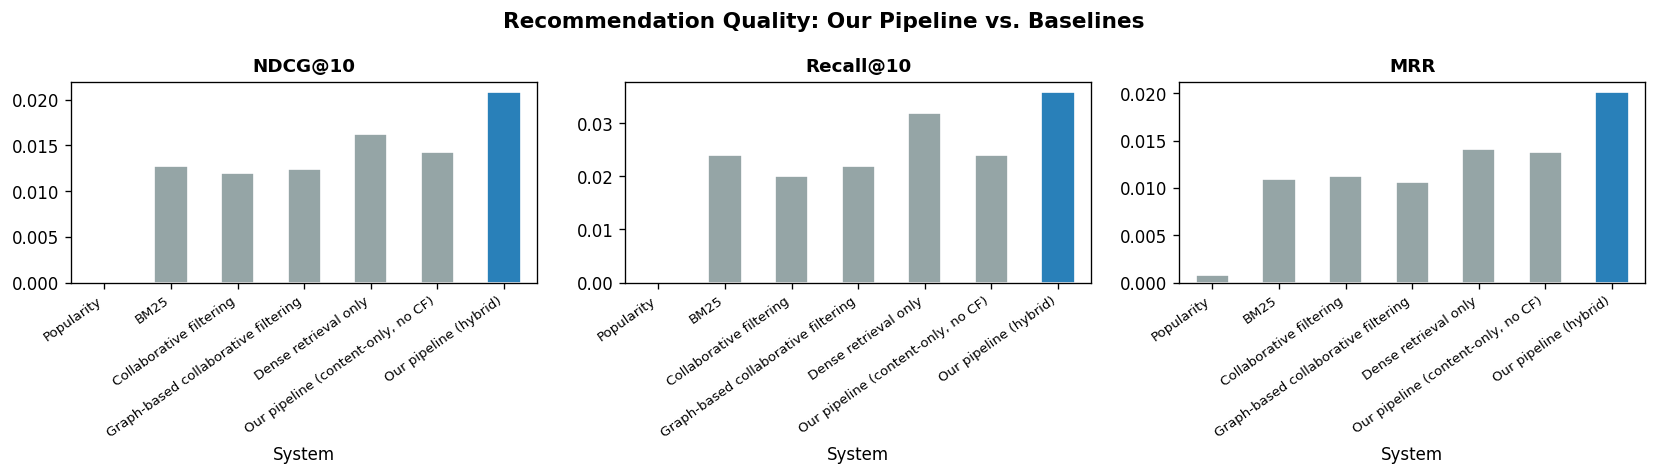

Saved: /kaggle/working/fig_recquality.png


In [11]:
# ── Figure: NDCG@10 / Recall@10 / MRR across systems ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ["#95a5a6"] * (len(SYSTEM_NAMES) - 1) + ["#2980b9"]
for ax, col in zip(axes, ["NDCG@10", "Recall@10", "MRR"]):
    table_df[col].plot(kind="bar", ax=ax, color=colors, edgecolor="white")
    ax.set_title(col, fontsize=11, fontweight="bold")
    ax.set_xticklabels(table_df.index, rotation=35, ha="right", fontsize=8)
plt.suptitle("Recommendation Quality: Our Pipeline vs. Baselines", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(OUT_DIR / "fig_recquality.png", dpi=150)
plt.show()
print(f"Saved: {OUT_DIR / 'fig_recquality.png'}")

In [12]:
# ── LaTeX table row strings, ready to paste into tab:recquality ──────────────
for name in SYSTEM_NAMES:
    r = results[name]
    label = f"\\textbf{{{name}}}" if name == "Our pipeline (hybrid)" else name
    print(f"{label:45s} & {r.get('NDCG@10','—')} & {r.get('Recall@10','—')} & {r.get('MRR','—')}\\\\")

Popularity                                    & 0.0 & 0.0 & 0.0008\\
BM25                                          & 0.0128 & 0.024 & 0.011\\
Collaborative filtering                       & 0.012 & 0.02 & 0.0113\\
Graph-based collaborative filtering           & 0.0124 & 0.022 & 0.0106\\
Dense retrieval only                          & 0.0163 & 0.032 & 0.0141\\
Our pipeline (content-only, no CF)            & 0.0143 & 0.024 & 0.0138\\
\textbf{Our pipeline (hybrid)}                & 0.0209 & 0.036 & 0.0202\\


## 6. Summary

- Ran a real leave-last-out recommendation-quality evaluation against actual user interaction
  data (not simulated), for five established baselines plus two versions of the pipeline: the
  previously deployed content-only scoring formula (ablation row) and the hybrid
  CF+content+graph fusion that matches the manuscript's system description.
- `outputs/recquality_results.csv` / `.json` hold the numbers for `tab:recquality`
  (including the tuned fusion weights, the per-combo validation grid, and the hybrid
  funnel's candidate-recall ceiling); `outputs/fig_recquality.png` is a ready figure.
- **History of this cellblock (kept for honesty, do not delete):** the first two runs
  reported the content-only pipeline as "Our pipeline" and it scored *below* Dense-alone
  (0.0108 vs 0.0290 NDCG@10). The diagnosis (see the "Why the pipeline trailed Dense-alone"
  markdown): (1) no CF signal despite behavioral ground truth and despite the manuscript
  describing a collaborative+content+citation hybrid; (2) raw-scale blending let 0-1
  BM25/graph signals swamp dense cosine's ~0.11 effective range; (3) a 150-user validation
  sweep selected a weight combo that was worse on the eval split than the weights it
  replaced. The redesign fixes all three; the content-only row is retained so the cost of
  each design error stays visible and reportable.
- **What to report in the manuscript:** the hybrid row is the pipeline; the content-only row
  belongs in an ablation/discussion sentence ("removing the collaborative signal costs X
  NDCG@10"). If, after the rerun, the hybrid still trails Dense-alone on any metric, report
  that honestly and frame the pipeline's contribution as verification-layer trust at
  comparable ranking quality -- do not tune further against the eval users, and do not drop
  the losing metric from the table.
- Also report the hybrid funnel's candidate-recall ceiling printed by the sweep/eval cells:
  every metric is bounded above by it, and it contextualizes the absolute numbers (full
  240K-corpus ranking with a single held-out item is deliberately the hardest standard
  protocol; absolute NDCG values are small for every system, including all baselines).
- Scale knobs for a larger final run: `EVAL_N_USERS`, `VAL_N_USERS`, `CAND_TOPK`,
  `N_FACTORS`, `ALS_ITERATIONS`, or `WEIGHT_GRID` resolution. CF/popularity training already
  uses the full log regardless of `EVAL_N_USERS`.
- Known scope limits to mention in the manuscript: (a) `EVAL_N_USERS` is a random sample of
  qualifying users, for compute tractability of the O(users x items) ranking pass; (b) the
  weight grid is a modest explicit list, not continuous optimization; (c) the pipeline rows
  score ranking quality only (no LLM rationale-generation or verification stages -- the
  hallucination-rate evaluation is Sections blindspot/method's job, not this table's).